In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
lr_model = joblib.load('../models/logistic_regression_text.pkl')
svm_model = joblib.load('../models/linear_svm.pkl')

print("Both models loaded successfully.")

Both models loaded successfully.


In [3]:
test_df = pd.read_csv('data/test.csv')

x_test = test_df['msg']
y_test = test_df['label']

print("Test Set Size:", len(test_df))

Test Set Size: 1519


In [4]:
y_pred_lr = lr_model.predict(x_test)
y_pred_svm = svm_model.predict(x_test)

print("Logistic Regression predictions:", len(y_pred_lr))
print("Linear SVM predictions:", len(y_pred_svm))

Logistic Regression predictions: 1519
Linear SVM predictions: 1519


In [5]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Spam Precision', 'Spam Recall',
               'Spam F1-score', 'Macro F1-score'],

    'Logistic Regression': [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr, pos_label='spam'),
        recall_score(y_test, y_pred_lr, pos_label='spam'),
        f1_score(y_test, y_pred_lr, pos_label='spam'),
        f1_score(y_test, y_pred_lr, average='macro')
    ],

    'Linear SVM': [
        accuracy_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_svm, pos_label='spam'),
        recall_score(y_test, y_pred_svm, pos_label='spam'),
        f1_score(y_test, y_pred_svm, pos_label='spam'),
        f1_score(y_test, y_pred_svm, average='macro')
    ]
})

comparison.round(4)

,Metric,Logistic Regression,Linear SVM
0,Accuracy,0.9717,0.9763
1,Spam Precision,0.9400,0.9664
2,Spam Recall,0.8057,0.8229
3,Spam F1-score,0.8677,0.8889
4,Macro F1-score,0.9259,0.9378


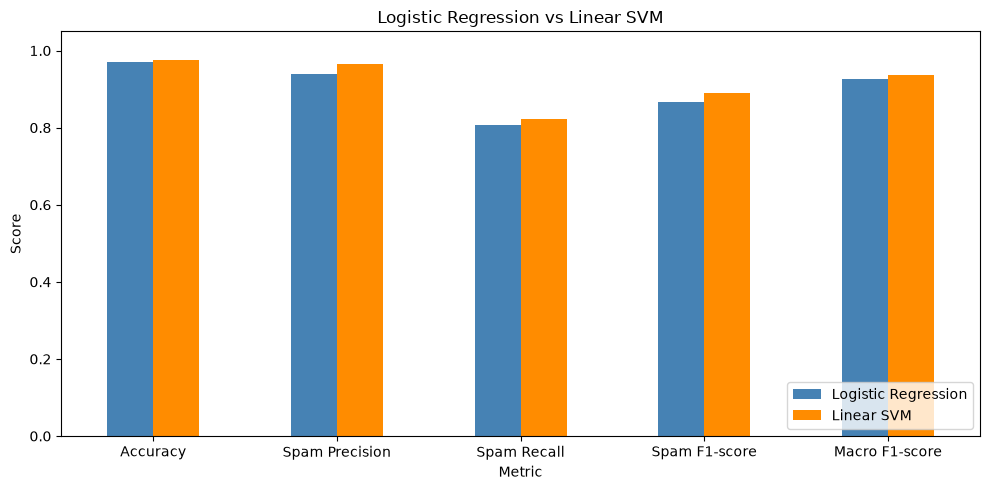

In [6]:
comparison.set_index('Metric').plot(
    kind='bar',
    figsize=(10, 5),
    color=['steelblue', 'darkorange'],
    rot=0
)

plt.title('Logistic Regression vs Linear SVM')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

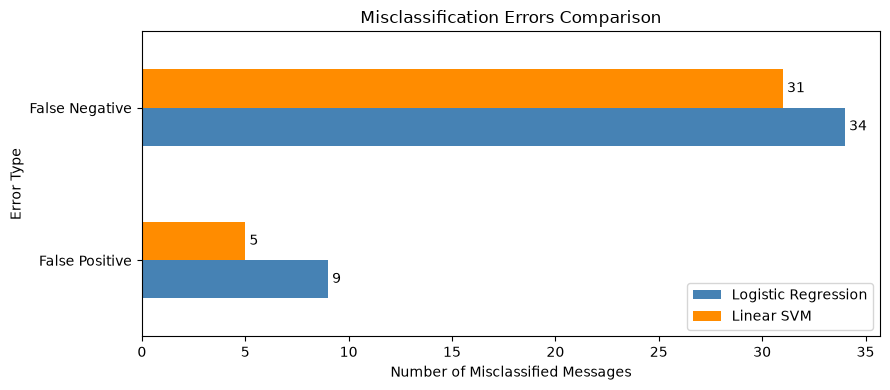

In [7]:
errors = pd.DataFrame({
    'Logistic Regression': [
        confusion_matrix(y_test, y_pred_lr, labels=['ham', 'spam'])[0, 1],
        confusion_matrix(y_test, y_pred_lr, labels=['ham', 'spam'])[1, 0]
    ],
    'Linear SVM': [
        confusion_matrix(y_test, y_pred_svm, labels=['ham', 'spam'])[0, 1],
        confusion_matrix(y_test, y_pred_svm, labels=['ham', 'spam'])[1, 0]
    ]
}, index=['False Positive', 'False Negative'])

ax = errors.plot(
    kind='barh',
    figsize=(9, 4),
    color=['steelblue', 'darkorange']
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Misclassification Errors Comparison')
plt.xlabel('Number of Misclassified Messages')
plt.ylabel('Error Type')
plt.legend()
plt.tight_layout()
plt.show()

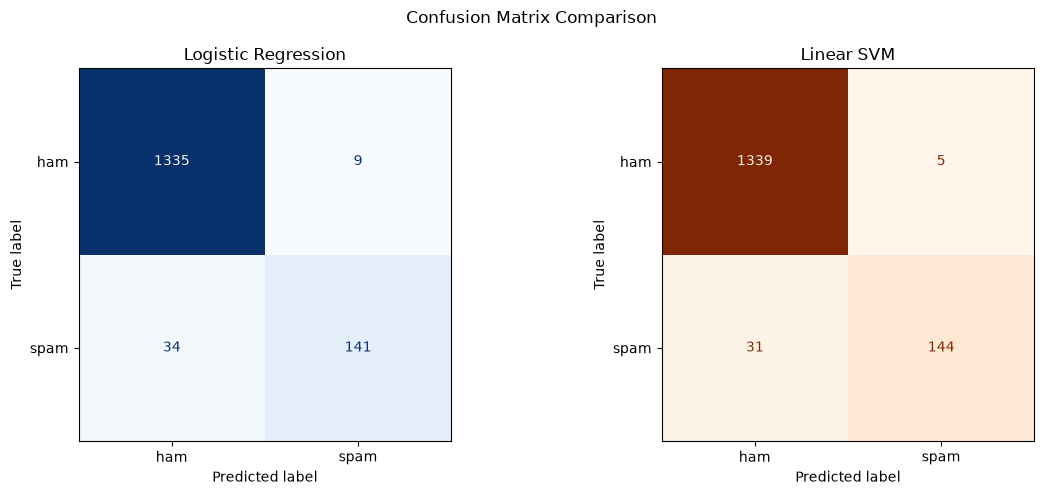

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr,
    labels=['ham', 'spam'],
    cmap='Blues',
    ax=axes[0],
    colorbar=False
)
axes[0].set_title('Logistic Regression')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_svm,
    labels=['ham', 'spam'],
    cmap='Oranges',
    ax=axes[1],
    colorbar=False
)
axes[1].set_title('Linear SVM')

plt.suptitle('Confusion Matrix Comparison')
plt.tight_layout()
plt.show()

In [9]:
results = comparison.set_index('Metric').T

best_model_name = results['Macro F1-score'].idxmax()

print("Best model based on test Macro F1-score:", best_model_name)

display(results.sort_values('Macro F1-score', ascending=False).round(4))

Best model based on test Macro F1-score: Linear SVM


Metric,Accuracy,Spam Precision,Spam Recall,Spam F1-score,Macro F1-score
Linear SVM,0.9763,0.9664,0.8229,0.8889,0.9378
Logistic Regression,0.9717,0.9400,0.8057,0.8677,0.9259


## Results and Discussion

Both Logistic Regression and Linear SVM achieved strong performance
in SMS spam classification using TF-IDF features.

However, Linear SVM achieved better test performance in terms of
Accuracy, Spam Precision, Recall, and F1-score.

Linear SVM also produced fewer false positives and false negatives,
making it more reliable for spam detection on this test set.

Its performance may be attributed to its ability to handle
high-dimensional, sparse text features and its maximum-margin
classification approach.

## Conclusion

Based on the test results, Linear SVM is selected as the preferred
model for the spam classification system and GUI integration.